## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
 4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Will Keenan

**Date:** 10/12/2026

In [14]:
#Question 1.1
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

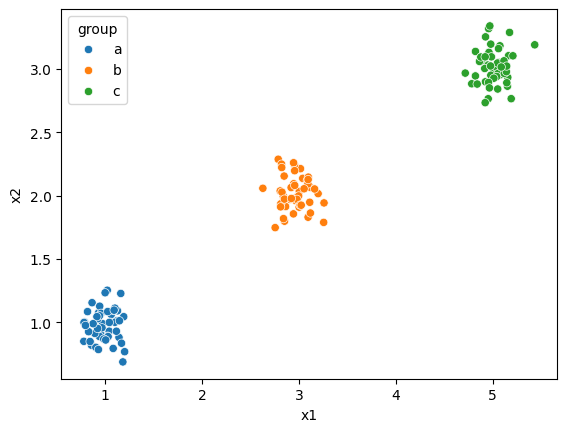

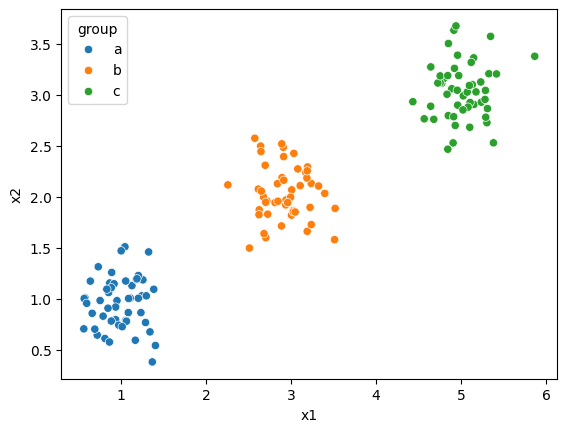

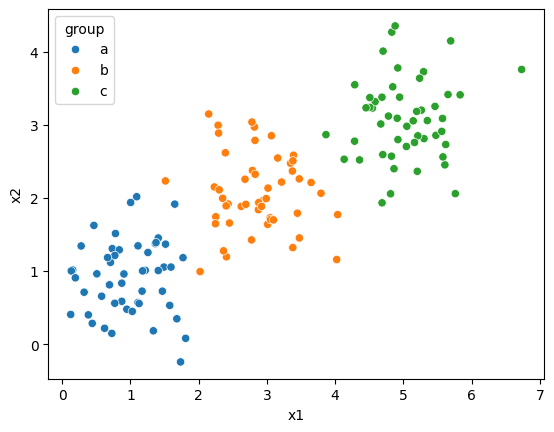

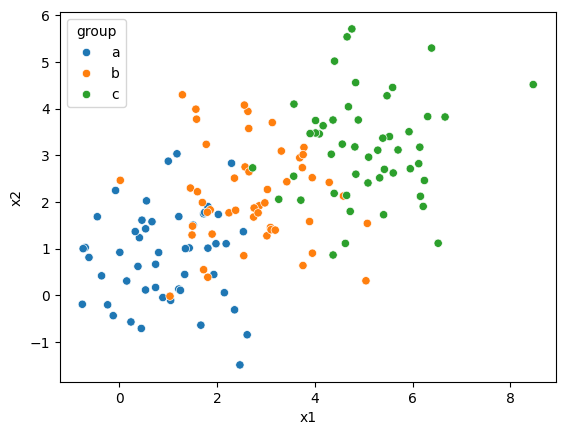

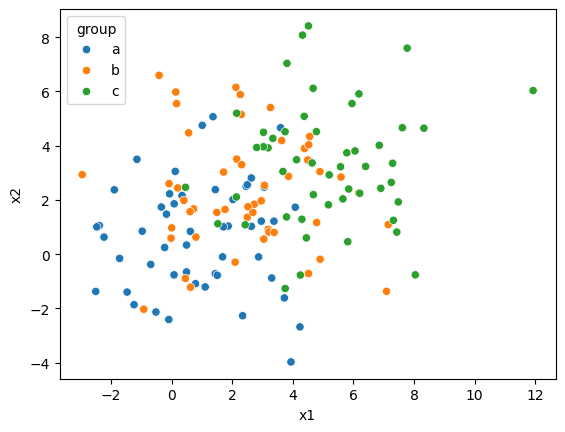

'\n0.125 and 0.25 the three clusters are tight and separate. At 0.5 they start to touch. At 1.0 and especially 2.0 they overlap heavily and look like one cloud.\n'

In [15]:
#Question 1.2:
import seaborn as sns
import matplotlib.pyplot as plt

for name, df in zip(['0.125','0.25','0.5','1.0','2.0'], [df0_125, df0_25, df0_5, df1_0, df2_0]):
    sns.scatterplot(data=df, x='x1', y='x2', hue='group')
    plt.show()

'''
0.125 and 0.25 the three clusters are tight and separate. At 0.5 they start to touch. At 1.0 and especially 2.0 they overlap heavily and look like one cloud.
'''

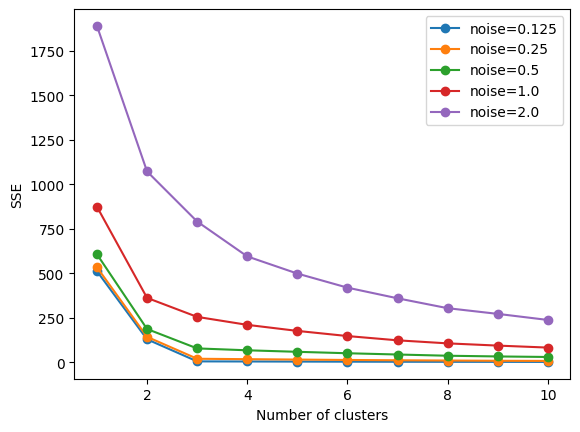

In [16]:
#Question 1.3
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

for name, d in zip(['0.125','0.25','0.5','1.0','2.0'], [df0_125, df0_25, df0_5, df1_0, df2_0]):
    SSE = [KMeans(n_clusters=k, n_init=10, random_state=100).fit(d[['x1', 'x2']]).inertia_
           for k in range(1, 11)]
    plt.plot(range(1, 11), SSE, marker='o', label=f'noise={name}')
plt.xlabel('Number of clusters'); plt.ylabel('SSE'); plt.legend()
plt.show()

'''
At low noise (0.125, 0.25) there is a sharp elbow at k = 3: SSE falls to about 1–4% of its k = 1 value and then barely changes.
As noise increases, the whole curve shifts upward and the bend softens. At 0.5 the elbow at 3 is still visible.
At 1.0 it’s weak, and at 2.0 the curve declines smoothly with no clear elbow (k = 3 → 4 still cuts SSE by about 25%).

With low noise I can confidently pick k = 3, which matches the true number of groups.
As noise increases, that choice becomes a judgment call, and at noise 2.0 I couldn’t defend k = 3 over 2 or 4 from the scree plot alone.
This matches the slides’ “No Clear Elbow” case: when the data doesn’t contain distinct groups, the elbow method doesn’t give a clear k.
'''

In [ ]:
#Question 1.4
'''
SSE is the total squared distance from each point to its assigned centroid.
Aadding clusters always lowers SSE, so we can’t simply minimize it; we look for where the improvement drops off.
In this simulation there are 3 true groups. While k < 3, at least one centroid has to cover two real groups, so its points are far from it.
 Adding a centroid separates a real group and causes a large drop in SSE (e.g., 512 → 129 → 4.9 at noise 0.125).
 Once k = 3, every group has its own centroid. Any extra centroid only splits a group into pieces, which barely reduces SSE (4.9 → 4.3).
 The elbow is that switch from big gains to small gains, and it sits at the true number of clusters.

Noise blurs this. When the groups overlap, the “real” splits don’t help as much, and splitting a wide, noisy group helps more.
The two kinds of gains end up similar in size, and the elbow disappears.
'''

In [19]:
#Question 2.1
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score, classification_report
!git clone https://github.com/willhk10-uva/A04-clustering
df = pd.read_csv('A04-clustering/data/SIPRI Military Expenditure Database.csv')
df = df.loc[df['Year'] == 2020, :]
df = df.dropna()
print(df.shape)
print(df.dtypes)
df.describe()

#After filtering to 2020 and dropping missing values there are 148 countries.
# All 4 variables are numeric so no type conversion is needed. the percent variables are stored as proportions.

fatal: destination path 'A04-clustering' already exists and is not an empty directory.
(148, 7)
index                               int64
Year                                int64
Country                            object
Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Spending    float64
Spending per Capita               float64
dtype: object


,index,Year,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
count,148.000000,148.0,148.000000,148.000000,148.000000,148.000000
mean,2831.256757,2020.0,13153.747670,0.019619,0.061510,268.264494
std,1654.299355,0.0,68005.236120,0.015033,0.046207,430.434878
min,32.000000,2020.0,8.622460,0.000054,0.004896,0.580129
25%,1409.000000,2020.0,204.877177,0.010413,0.031352,20.553464
50%,2871.000000,2020.0,959.535443,0.015324,0.047402,81.506703
75%,4222.500000,2020.0,5289.998320,0.024327,0.084681,326.267753
max,5880.000000,2020.0,778397.200000,0.098470,0.303027,2520.398541


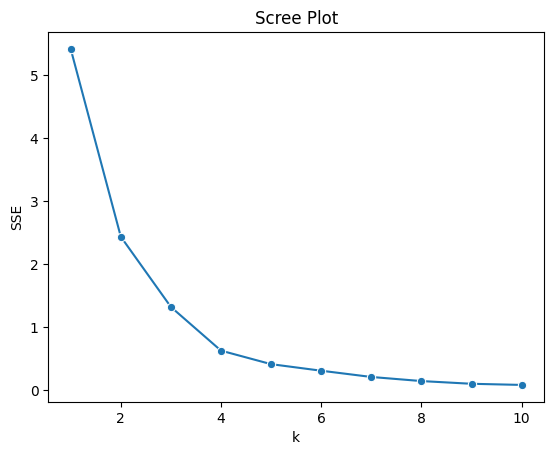

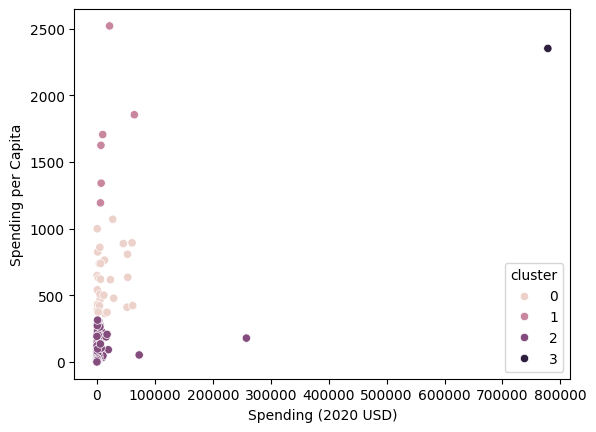

5540    3
Name: cluster, dtype: int32


Spending (2020 USD)                                              \
                      count           mean           std            min   
cluster                                                                   
0                      30.0   17077.591354  20583.053357     405.790494   
1                       6.0   19443.362047  22861.507114    6095.708713   
2                     111.0    4859.185065  25405.739131       8.622460   
3                       1.0  778397.200000           NaN  778397.200000   

                                                                     \
                   25%            50%            75%            max   
cluster                                                               
0          2294.039665    5857.060906   26296.001003   61712.537169   
1          7023.251766    8624.225729   18857.070183   64558.400000   
2           130.010211     382.464677    2297.032353  257973.429834   
3        778397.200000  778397.200000  778397.200000  778397.200000   

        Spending per Capita                                        \
                      count         mean         std          min   
cluster                                                             
0                      30.0   607.478618  206.928757   362.467076   
1                       6.0  1706.721916  466.375705  1193.598730   
2                     111.0    80.061470   83.501824     0.580129   
3                       1.0  2351.631858         NaN  2351.631858   

                                                             
                 25%          50%          75%          max  
cluster                                                      
0         422.208252   579.004604   757.328513  1070.623322  
1        1412.083201  1665.447478  1817.219993  2520.398541  
2          14.880549    47.056944   125.387558   314.201312  
3        2351.631858  2351.631858  2351.631858  2351.631858

In [21]:
#Question 2.2
def scree(X):
    ks = np.arange(1, 11)
    SSE = [KMeans(n_clusters=k, n_init=10, random_state=0).fit(X).inertia_ for k in ks]
    sns.lineplot(x=ks, y=SSE, marker='o').set(title='Scree Plot', xlabel='k', ylabel='SSE')
    plt.show()

cols = ['Spending (2020 USD)', 'Spending per Capita']

X = df[cols]
X = (X - X.min()) / (X.max() - X.min())
scree(X)

df['cluster'] = KMeans(n_clusters=4, n_init=10, random_state=0).fit(X).labels_

sns.scatterplot(data=df, x=cols[0], y=cols[1], hue='cluster')
plt.show()

print(df.loc[df['Country'] == 'United States of America', 'cluster'])
df.groupby('cluster')[cols].describe()

'''
I chose k=4 since the scree plot drops sharply up to k=3-4 and flattens out after that
The united states is in cluster 3. The US spends about 778 billion which is about 30x more than
the next-largest cluster's average. It's such a large outlier that k-means gives it its own cluster.
'''

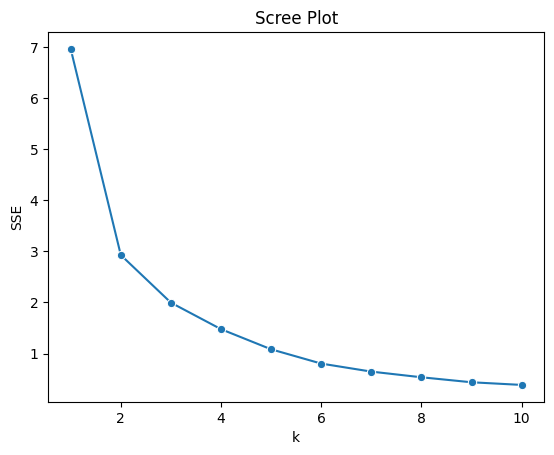

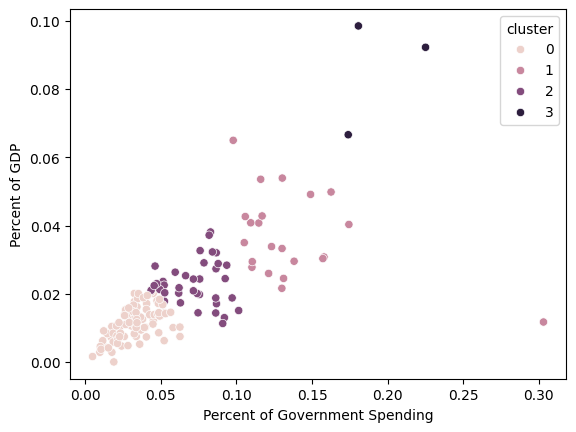

5540    2
Name: cluster, dtype: int32


"\nThe scree plot bends around k = 2–3 and flattens gradually after that, so the elbow is less sharp than in 2.2. \nI used k = 4 for comparison. The clusters are much more balanced (86 / 37 / 22 / 3) and order countries by military “burden”:\n\nLow burden (86): about 3% of government spending and 1% of GDP. Most of Europe, plus China and Australia.\nModerate (37): about 7% of government spending and 2.3% of GDP. The United States is here, along with India, Greece, and Ukraine.\nHigh (22): about 14% and 3.7%. Russia, Israel, Kuwait, Pakistan, Azerbaijan, Armenia, Jordan.\nExtreme (3): Oman, Saudi Arabia, and Algeria, at about 19% of government spending and 8.6% of GDP.\n\nFor comparison, in 2.2 the US was an outlier in its own cluster, but measured relative to its economy it's just a mid-level spender.\nThe clusters now reflect regional security situations (like the middle east, caucasus, russia) as opposed to country size or wealth\n"

In [25]:
#Question 2.3
cols2 = ['Percent of Government Spending', 'Percent of GDP']

X = df[cols2]
X = (X - X.min()) / (X.max() - X.min())
scree(X)

df['cluster'] = KMeans(n_clusters=4, n_init=10, random_state=0).fit(X).labels_

sns.scatterplot(data=df, x=cols2[0], y=cols2[1], hue='cluster')
plt.show()

print(df.loc[df['Country'] == 'United States of America', 'cluster'])
df.groupby('cluster')[cols2].describe()

'''
The scree plot bends around k = 2–3 and flattens gradually after that, so the elbow is less sharp than in 2.2.
I used k = 4 for comparison. The clusters are much more balanced (86 / 37 / 22 / 3) and order countries by military “burden”:

Low burden (86): about 3% of government spending and 1% of GDP. Most of Europe, plus China and Australia.
Moderate (37): about 7% of government spending and 2.3% of GDP. The United States is here, along with India, Greece, and Ukraine.
High (22): about 14% and 3.7%. Russia, Israel, Kuwait, Pakistan, Azerbaijan, Armenia, Jordan.
Extreme (3): Oman, Saudi Arabia, and Algeria, at about 19% of government spending and 8.6% of GDP.

For comparison, in 2.2 the US was an outlier in its own cluster, but measured relative to its economy it's just a mid-level spender.
The clusters now reflect regional security situations (like the middle east, caucasus, russia) as opposed to country size or wealth
'''

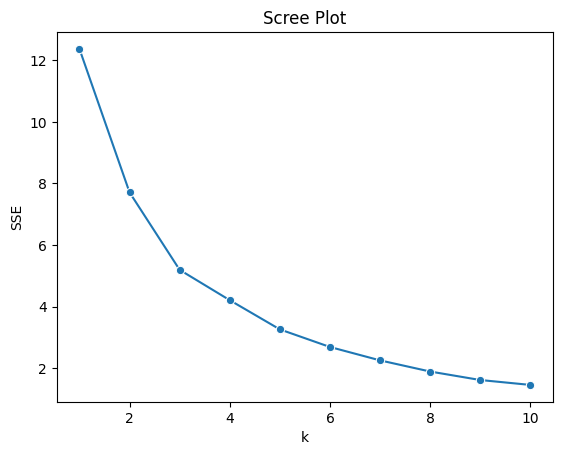

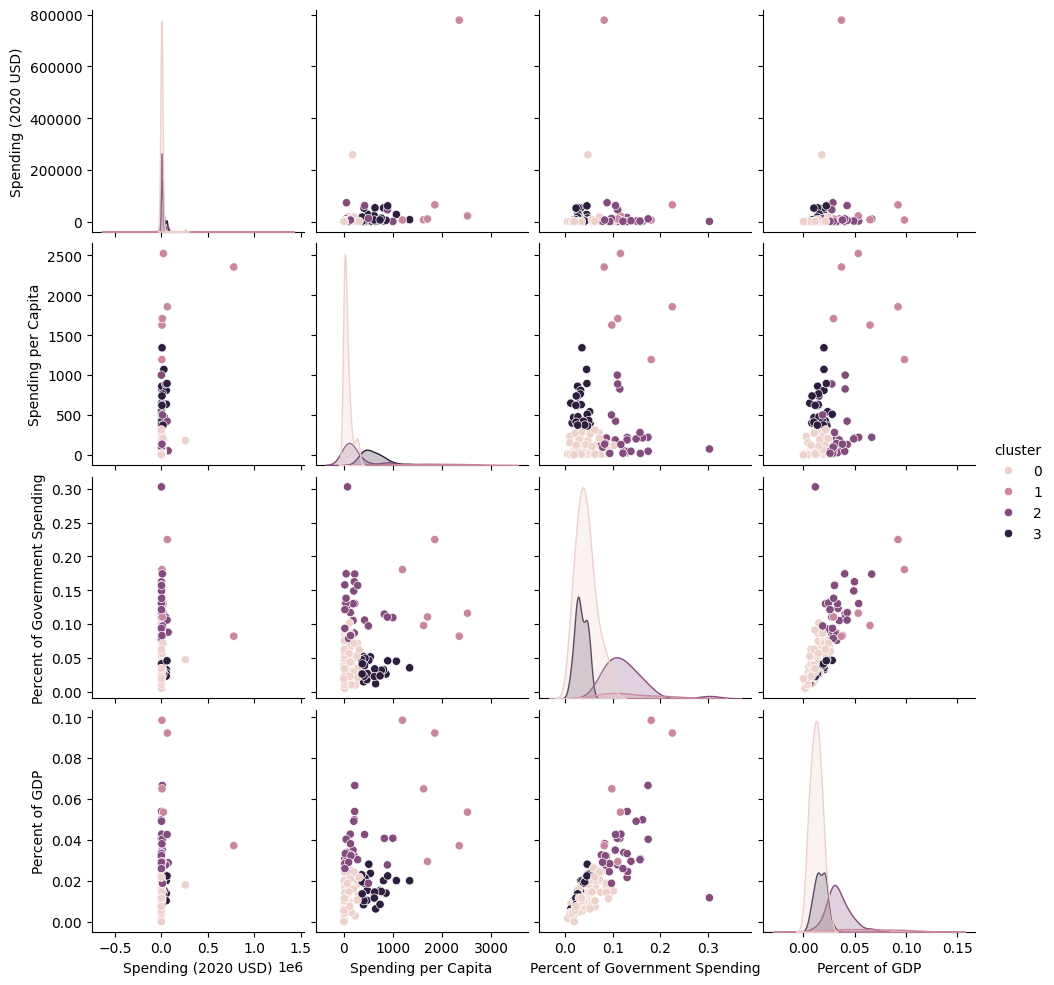

5540    1
Name: cluster, dtype: int32


Spending (2020 USD)                                             \
                      count           mean            std          min   
cluster                                                                  
0                      86.0    4513.543790   27841.230783     8.622460   
1                       6.0  147964.582042  309635.189564  6095.708713   
2                      30.0    9073.543709   18135.032885   163.926877   
3                      26.0   15330.618681   18923.469359   405.790494   

                                                                 \
                 25%           50%           75%            max   
cluster                                                           
0          81.022976    288.061512   1138.618231  257973.429834   
1        7700.424616  15897.570598  53872.942442  778397.200000   
2         522.737081   1663.090134   8646.648849   72937.064048   
3        3176.345598   5857.060906  21818.934764   60675.039625   

        Spending per Capita               ... Percent of Government Spending  \
                      count         mean  ...                            75%   
cluster                                   ...                                  
0                      86.0    70.290644  ...                       0.053006   
1                       6.0  1875.150751  ...                       0.164503   
2                      30.0   215.920971  ...                       0.136403   
3                      26.0   612.677541  ...                       0.044645   

                  Percent of GDP                                          \
              max          count      mean       std       min       25%   
cluster                                                                    
0        0.101501           86.0  0.012481  0.005799  0.000054  0.007811   
1        0.225050            6.0  0.062634  0.028275  0.029429  0.041272   
2        0.303027           30.0  0.034105  0.011116  0.011742  0.027933   
3        0.052209           26.0  0.016585  0.005525  0.006273  0.013689   

                                       
              50%       75%       max  
cluster                                
0        0.012532  0.016783  0.026340  
1        0.059257  0.085398  0.098470  
2        0.032148  0.040637  0.066600  
3        0.015324  0.020431  0.028132  

[4 rows x 32 columns]

In [24]:
# Question 2.4
cols = ['Spending (2020 USD)', 'Spending per Capita',
        'Percent of Government Spending', 'Percent of GDP']
X = df[cols]
X = (X - X.min()) / (X.max() - X.min())

scree(X)

df['cluster'] = KMeans(n_clusters=4, n_init=10, random_state=0).fit(X).labels_

sns.pairplot(df[cols + ['cluster']], hue='cluster')
plt.show()

print(df.loc[df['Country'] == 'United States of America', 'cluster'])
df.groupby('cluster')[cols].describe()

'''
The scree plot has no clear elbow, so k is harder to choose. I kept k=4. The clusters mix both of the views that were discussed earlier
* big, heavy spenders (6) like the us, saudi arabia, israel, kuwait, oman, singapore, are high in both dollars and burden
* high burden, low dollars (30) l;ike russia, algeria, pakistan, ukraine, jordan, azerbaijan
* wealthy, low burden (26): UK, France, poland, greece, australia, norway, are mopderate per capita and low percent of gdp
* low on everything (86)
'''

In [ ]:
#Question 2.5

'''
Partly. k-means separated two different ideas: how much countries spend (dollars and per capita) and how heavily spending weighs on their economies (percentages).
It also showed that the US is an outlier in absolute terms but not relative to its economy.
Combining all four variables gave the most interpretable groups, roughly aligned with wealth and regional security.

The limitations matter, though. The dollar variables are extremely skewed, so in 2.2 a single country used up a whole cluster and 111 countries were lumped together.
The elbows were weak in 2.3 and 2.4, so k = 4 was a judgment call. A log transform of the dollar variables, or a different algorithm
such as the hierarchical clustering in the slides, might give more useful groups.
'''

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

:- **Phase 1 commit SHA ID:** 1abdc02350c2d9317edac9eec6aaf164131899a1
- **AI tool and model used:** Opus 5.5 Medium

### *Prompts used

1. *Inserted all Questions with Answers into AI * Please review the following answers with accuracy and compare them to the rubric *pasted in rubric* Please sort your response into two distinct sections - one will be the AI proposed changes, bulleted out, and the second section will be the AI assisted solution.
2. Please format all of your responses in Markdown.

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

- **Q1.2:** Put the five scatterplots on one row of subplots with shared axes, and title each with its noise level. Right now each plot autoscales its own axes and has no title, so the plots are hard to compare and the `name` variable is never used.
- **Q1.3:** Add a second panel showing SSE divided by SSE at k=1. On the raw axis the noise=2.0 curve (SSE 1889 at k=1) flattens the low-noise curves, so their elbows are hard to see.
- **Q1.4:** Fix the typo "Aadding".
- **Q2.1:** In the cleaning answer, note that `index` is a leftover row-number column and `Year` is constant after filtering, so neither is a feature. Also note that spending is in millions of USD and that there are no duplicate countries.
- **Q2.1:** Remove the unused imports (`train_test_split`, `KNeighborsClassifier`, `accuracy_score`, etc.).
- **Q2.2:** Correct "about 30x more than the next-largest cluster's average". The US spends $778,397M and the largest other cluster mean is $19,443M, so the ratio is about **40x**.
- **Q2.2:** Expand the short answer to cover all four clusters and their sizes (111 / 30 / 6 / 1), and point out that China ($258B, the second-largest spender) lands in the 111-country low cluster. This is what rubric 2e ("what you see… patterns") asks for.
- **Q2.3:** Change k to 3 to match the elbow at 2–3.
- **Q2.4:** Correct the claim that the US is "high in both dollars and burden". The US spends 3.7% of GDP and 8.2% of government spending, which is moderate (2.3 placed it in the moderate cluster). It joins the big-spender group because of its dollar figures. Also note that the US is no longer alone in a cluster once four variables share the distance calculation.
- **Q2.4:** Fix the typos "l;ike" and "mopderate".
- **Scree helper:** Add a `title` argument so each scree plot says which variables it uses.
- **Q2.5:** Add a new section that redoes the analysis with log-transformed dollar variables.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | Rubric 2b/2c depend on comparing distinctness. Shared axes make the spread visible, and I confirmed the cluster centers (1,1), (3,2), (5,3) are unchanged. |
| 2 | Modify | Keep the original single-canvas plot as the main answer and add the normalized panel next to it. Verified: SSE(3)/SSE(1) = 1.0%, 3.7%, 12.8%, 29.2%, 41.8% across noise levels, which supports the existing "1–4%" claim. |
| 3 | Accept | Typo only. Verified the numbers in that cell: 511.6 → 128.9 → 4.9 → 4.3 at noise 0.125. |
| 4 | Accept | Addresses rubric 1b directly. Verified: 148 rows, 0 duplicate countries, percentages max at 0.098 and 0.303 (proportions), US = 778,397 (millions). |
| 5 | Accept | Cosmetic; nothing depends on those imports. |
| 6 | Accept | Verified cluster means: 17,078 / 19,443 / 4,859 / 778,397. 778,397 / 19,443 ≈ 40. |
| 7 | Accept | Verified memberships: the 6 are Israel, Kuwait, Norway, Oman, Saudi Arabia, Singapore; the 30 are mostly wealthy OECD countries plus Russia and Taiwan; China and India are in the 111. |
| 8 | Reject | SSE drops 26% from k=3 to 4 and 27% from 4 to 5, so neither choice is clearly right. Keeping k=4 everywhere makes 2.2, 2.3 and 2.4 comparable. I added one sentence saying this instead. |
| 9 | Accept | Verified the US values: 3.72% of GDP and 8.2% of government spending; the big-spender cluster averages 6.3% of GDP. |
| 10 | Accept | Typos only. |
| 11 | Accept | Small readability improvement with no effect on results. |
| 12 | Reject | Not asked for, and 2.5 already mentions a log transform as a limitation. That is enough for the 3 rubric points. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

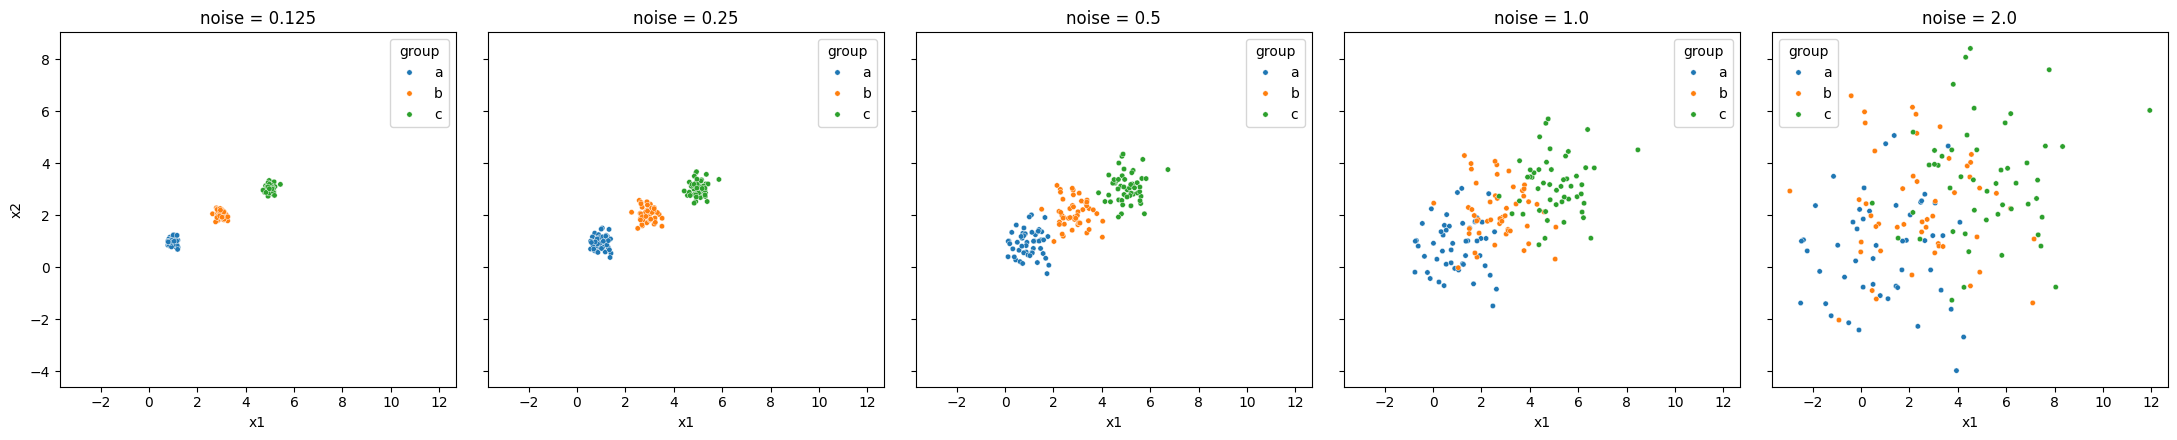

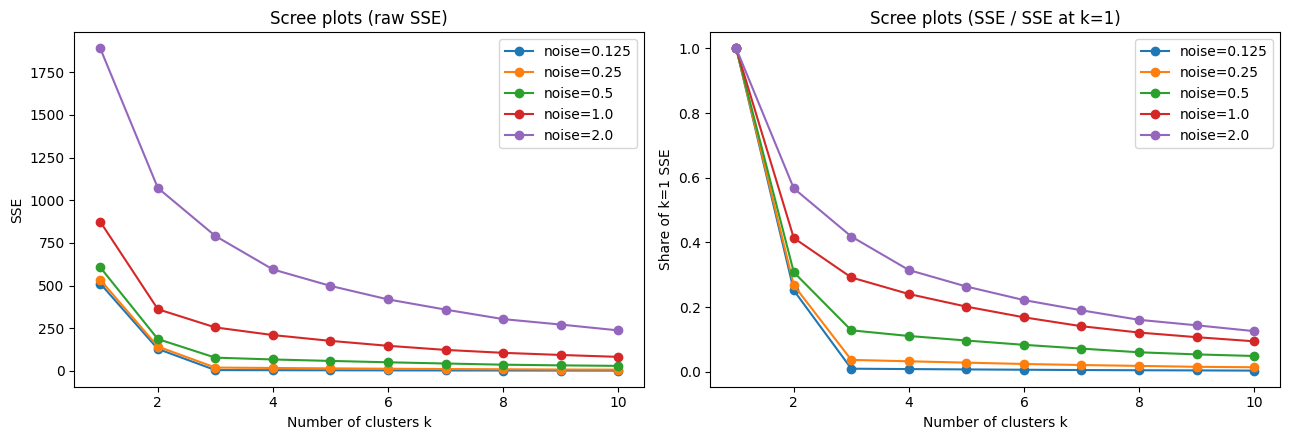

fatal: destination path 'A04-clustering' already exists and is not an empty directory.
(148, 7)
index                               int64
Year                                int64
Country                            object
Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Spending    float64
Spending per Capita               float64
dtype: object
Duplicate countries: 0


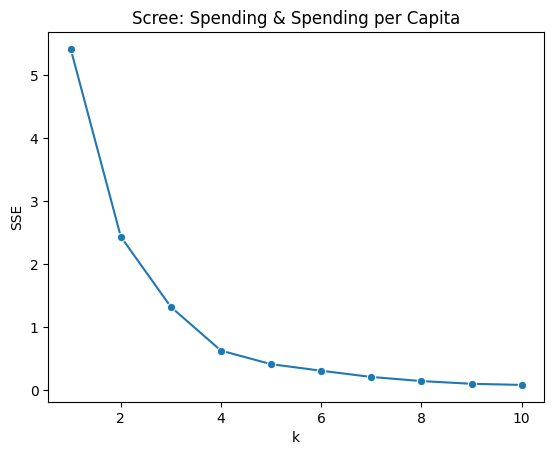

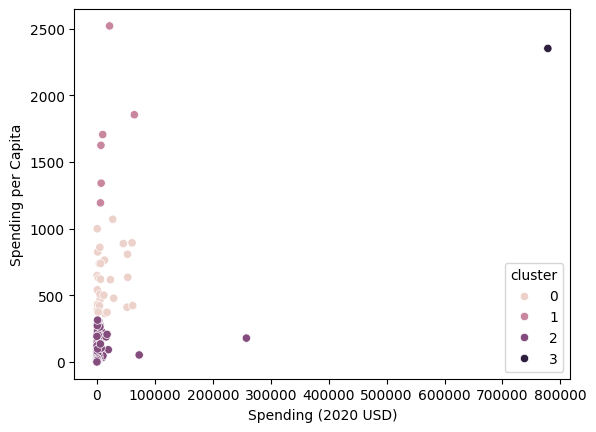

cluster
2    111
0     30
1      6
3      1
Name: count, dtype: int64
5540    3
Name: cluster, dtype: int32


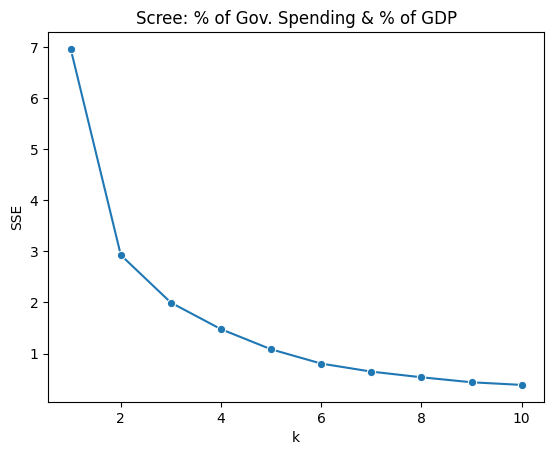

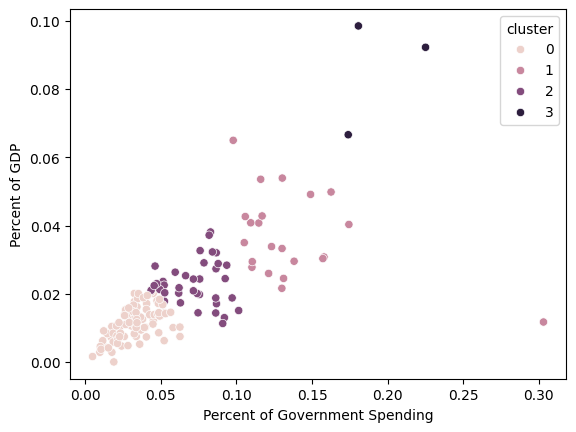

cluster
0    86
2    37
1    22
3     3
Name: count, dtype: int64
5540    2
Name: cluster, dtype: int32


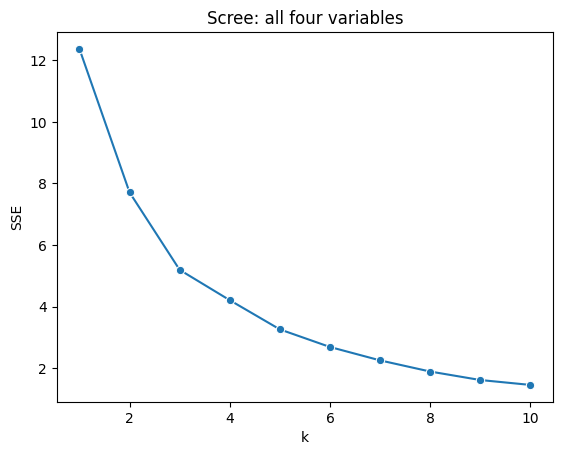

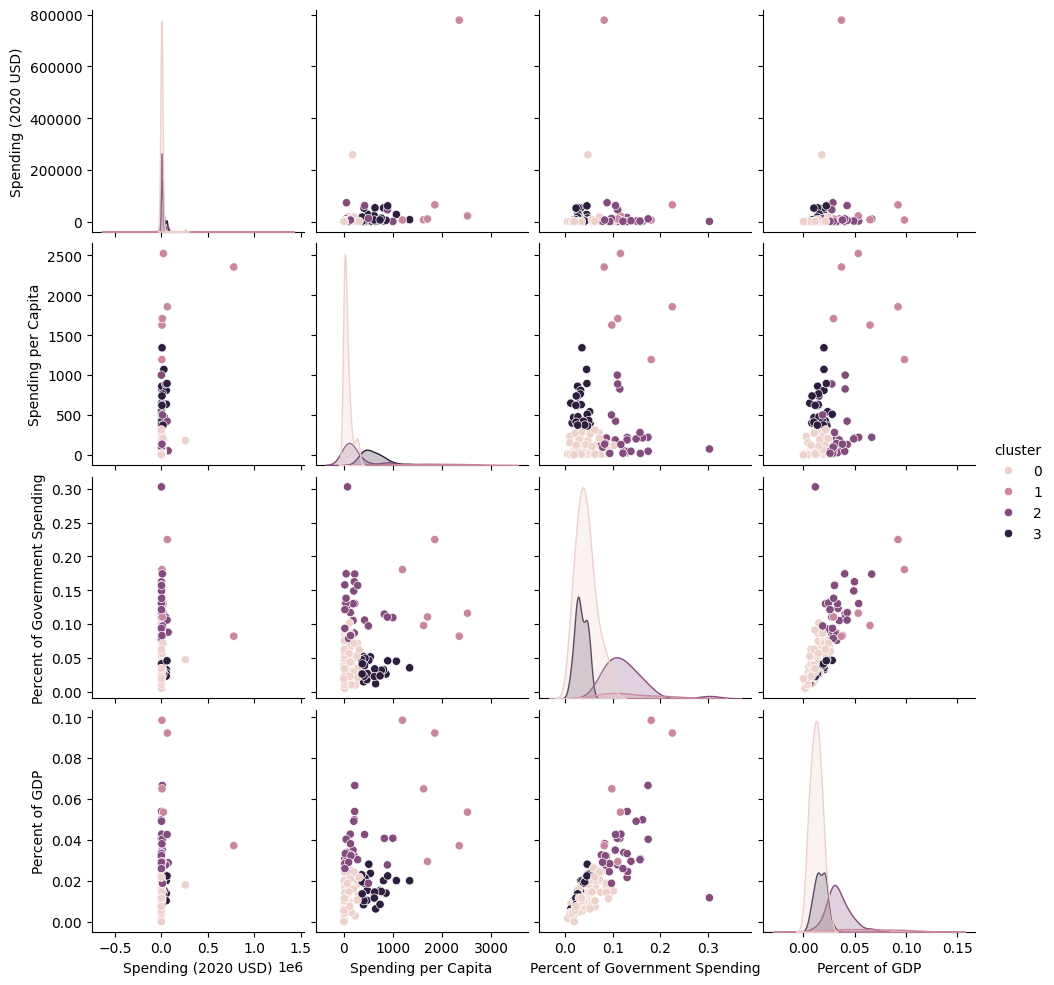

cluster
0    86
2    30
3    26
1     6
Name: count, dtype: int64
5540    1
Name: cluster, dtype: int32


'\n**Partly.** k-means separated two different ideas:\n \n- **How much** countries spend (dollars and per capita)\n- **How heavily** spending weighs on their economies (percentages)\nIt also showed that the US is an outlier in absolute terms but not relative to its economy. Combining all four variables gave the most interpretable groups, roughly aligned with wealth and regional security.\n \n**The limitations matter, though:**\n \n- The dollar variables are extremely skewed, so in 2.2 a single country used up a whole cluster, 111 countries were lumped together, and even China landed in the low group.\n- The elbows were weak in 2.3 and 2.4, so k = 4 was a judgment call.\n- A log transform of the dollar variables, or a different algorithm such as hierarchical clustering, might give more useful groups.\n'

In [31]:
### Question 1.2

import seaborn as sns
import matplotlib.pyplot as plt

datasets = {'0.125': df0_125, '0.25': df0_25, '0.5': df0_5, '1.0': df1_0, '2.0': df2_0}

fig, axes = plt.subplots(1, 5, figsize=(22, 4.5), sharex=True, sharey=True)
for ax, (name, d) in zip(axes, datasets.items()):
    sns.scatterplot(data=d, x='x1', y='x2', hue='group', s=15, ax=ax)
    ax.set_title(f'noise = {name}')
plt.tight_layout()
plt.show()

'''

At noise **0.125** and **0.25** the three clusters are tight and clearly separated. At **0.5** they start to touch. At **1.0** they overlap heavily, and at **2.0** the groups blend into one large cloud. With shared axes you can also see the cloud spreading far beyond the true centers (1,1), (3,2), (5,3).
'''
### Question 1.3

from sklearn.cluster import KMeans

ks = range(1, 11)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
for name, d in datasets.items():
    SSE = [KMeans(n_clusters=k, n_init=10, random_state=100).fit(d[['x1', 'x2']]).inertia_ for k in ks]
    ax1.plot(ks, SSE, marker='o', label=f'noise={name}')
    ax2.plot(ks, [s / SSE[0] for s in SSE], marker='o', label=f'noise={name}')
ax1.set(title='Scree plots (raw SSE)', xlabel='Number of clusters k', ylabel='SSE')
ax2.set(title='Scree plots (SSE / SSE at k=1)', xlabel='Number of clusters k', ylabel='Share of k=1 SSE')
ax1.legend(); ax2.legend()
plt.tight_layout()
plt.show()
'''
**Effect of noise on the scree plot:**

| Noise | SSE(k=3) as share of SSE(k=1) | Elbow |
|---|---|---|
| 0.125 | 1.0% | Sharp at k = 3 |
| 0.25 | 3.7% | Sharp at k = 3 |
| 0.5 | 12.8% | Still visible at k = 3 |
| 1.0 | 29.2% | Weak |
| 2.0 | 41.8% | None; k = 3 → 4 still cuts SSE by about 25% |

As noise increases, the whole curve shifts upward and the bend softens.

**Ability to pick k:** With low noise I can confidently pick k = 3, which matches the true number of groups. As noise increases, that choice becomes a judgment call, and at noise 2.0 I couldn't defend k = 3 over 2 or 4 from the scree plot alone. When the data doesn't contain distinct groups, the elbow method doesn't give a clear k.
'''
### Question 1.4
'''
SSE is the total squared distance from each point to its assigned centroid. Adding clusters always lowers SSE, so we can't simply minimize it; we look for where the improvement drops off.

In this simulation there are 3 true groups:

- **While k < 3**, at least one centroid has to cover two real groups, so its points are far from it. Adding a centroid separates a real group and causes a large drop in SSE (e.g., 512 → 129 → 4.9 at noise 0.125).
- **Once k = 3**, every group has its own centroid. Any extra centroid only splits a group into pieces, which barely reduces SSE (4.9 → 4.3).
The elbow is that switch from big gains to small gains, and it sits at the true number of clusters.

**Noise blurs this.** When the groups overlap, the "real" splits don't help as much, and splitting a wide, noisy group helps more. The two kinds of gains end up similar in size, and the elbow disappears.
'''

### Question 2.1

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

!git clone https://github.com/willhk10-uva/A04-clustering
df = pd.read_csv('A04-clustering/data/SIPRI Military Expenditure Database.csv')
df = df.loc[df['Year'] == 2020, :]
df = df.dropna()
print(df.shape)
print(df.dtypes)
print('Duplicate countries:', df['Country'].duplicated().sum())
df.describe()

'''

After filtering to 2020 and dropping missing values there are **148 countries**, with no duplicates.

- All four spending variables are already numeric (float), so no type conversion or string cleaning is needed.
- The percent variables are stored as proportions (e.g., 0.037 = 3.7%), and `Spending (2020 USD)` is in **millions** of dollars.
- `index` is a leftover row-number column and `Year` is constant after filtering, so neither is used as a clustering feature.
'''
### Question 2.2

def scree(X, title='Scree Plot'):
    ks = np.arange(1, 11)
    SSE = [KMeans(n_clusters=k, n_init=10, random_state=0).fit(X).inertia_ for k in ks]
    sns.lineplot(x=ks, y=SSE, marker='o').set(title=title, xlabel='k', ylabel='SSE')
    plt.show()

cols = ['Spending (2020 USD)', 'Spending per Capita']

X = df[cols]
X = (X - X.min()) / (X.max() - X.min())
scree(X, 'Scree: Spending & Spending per Capita')

df['cluster'] = KMeans(n_clusters=4, n_init=10, random_state=0).fit(X).labels_

sns.scatterplot(data=df, x=cols[0], y=cols[1], hue='cluster')
plt.show()

print(df['cluster'].value_counts())
print(df.loc[df['Country'] == 'United States of America', 'cluster'])
df.groupby('cluster')[cols].describe()
'''

**Choice of k:** I chose k = 4. SSE drops sharply up to k = 4 (5.41 → 2.44 → 1.32 → 0.63) and flattens after that.

**Clusters** (very unbalanced: 111 / 30 / 6 / 1):

| Cluster | Size | Members | Profile |
|---|---|---|---|
| United States | 1 | USA | About $778 billion, roughly 40x the next-largest cluster's average |
| Small, rich, high per-capita | 6 | Israel, Kuwait, Norway, Oman, Saudi Arabia, Singapore | Modest totals, about $1,700 per person |
| Wealthy developed | 30 | Most of Western Europe, Japan, South Korea, Australia, Canada, Russia, Taiwan | About $600 per person |
| Everyone else | 111 | Includes China ($258B) and India | About $80 per person |

**Where is the US?** In a cluster of its own. It is such an extreme outlier that k-means gives it a whole cluster.

**Patterns:** The clusters mostly sort countries by per-capita spending (roughly by wealth), while the total-spending axis is dominated by the US. Because max-min scaling sets the US to 1, China ends up at only 0.33 and lands in the low cluster despite being the second-largest spender.
'''
### Question 2.3

cols2 = ['Percent of Government Spending', 'Percent of GDP']

X = df[cols2]
X = (X - X.min()) / (X.max() - X.min())
scree(X, 'Scree: % of Gov. Spending & % of GDP')

df['cluster'] = KMeans(n_clusters=4, n_init=10, random_state=0).fit(X).labels_

sns.scatterplot(data=df, x=cols2[0], y=cols2[1], hue='cluster')
plt.show()

print(df['cluster'].value_counts())
print(df.loc[df['Country'] == 'United States of America', 'cluster'])
df.groupby('cluster')[cols2].describe()

'''

**Choice of k:** The scree plot bends around k = 2–3 and then flattens gradually, so the elbow is less sharp than in 2.2. I kept k = 4 so the results are directly comparable with 2.2 and 2.4 (k = 3 → 4 and 4 → 5 both cut SSE by about 26%, so neither choice is clearly better).

**Clusters** (much more balanced: 86 / 37 / 22 / 3), ordered by military "burden":

| Cluster | Size | % of gov. spending | % of GDP | Examples |
|---|---|---|---|---|
| Low burden | 86 | ~3% | ~1% | Much of Western Europe, China, Norway, Australia |
| Moderate | 37 | ~7% | ~2.3% | **United States**, India, UK, Poland, Greece, Ukraine |
| High | 22 | ~14% | ~3.7% | Russia, Israel, Kuwait, Pakistan, Iran, Azerbaijan, Armenia, Jordan |
| Extreme | 3 | ~19% | ~8.6% | Oman, Saudi Arabia, Algeria |

**Comparison to part 2:** In 2.2 the US was an outlier in its own cluster, but measured relative to its economy it is just a moderate spender. The clusters now reflect security situations (the Middle East, the Caucasus, Russia, active conflict zones) rather than country size or wealth.
'''
### Question 2.4

cols = ['Spending (2020 USD)', 'Spending per Capita',
        'Percent of Government Spending', 'Percent of GDP']
X = df[cols]
X = (X - X.min()) / (X.max() - X.min())

scree(X, 'Scree: all four variables')

df['cluster'] = KMeans(n_clusters=4, n_init=10, random_state=0).fit(X).labels_

sns.pairplot(df[cols + ['cluster']], hue='cluster')
plt.show()

print(df['cluster'].value_counts())
print(df.loc[df['Country'] == 'United States of America', 'cluster'])
df.groupby('cluster')[cols].describe()
'''

**Choice of k:** The scree plot has no clear elbow (12.4 → 7.7 → 5.2 → 4.2 → 3.3), so k is harder to choose. I kept k = 4.

**Clusters** combine the two views from 2.2 and 2.3:

| Cluster | Size | Examples | Profile |
|---|---|---|---|
| Big or rich spenders | 6 | US, Saudi Arabia, Israel, Kuwait, Oman, Singapore | High in dollars; most also high in burden (cluster average ~6% of GDP) |
| High burden, low dollars | 30 | Russia, Algeria, Pakistan, India, Ukraine, Jordan, Azerbaijan, Iran | Large share of economy, small totals |
| Wealthy, low burden | 26 | UK, France, Germany, Poland, Greece, Australia, Norway, Japan | Moderate per capita, low share of GDP |
| Low on everything | 86 | Includes China | Low on all four variables |

The US is in the big-spender group because of its dollar figures; its own burden is moderate (3.7% of GDP, 8.2% of government spending).

**Comparison to previous parts:** The US no longer gets a cluster to itself, because its outlying dollar values now share the distance calculation with two variables where it is ordinary. The groups are the most interpretable of the three runs.
'''
### Question 2.5
'''
**Partly.** k-means separated two different ideas:

- **How much** countries spend (dollars and per capita)
- **How heavily** spending weighs on their economies (percentages)
It also showed that the US is an outlier in absolute terms but not relative to its economy. Combining all four variables gave the most interpretable groups, roughly aligned with wealth and regional security.

**The limitations matter, though:**

- The dollar variables are extremely skewed, so in 2.2 a single country used up a whole cluster, 111 countries were lumped together, and even China landed in the low group.
- The elbows were weak in 2.3 and 2.4, so k = 4 was a judgment call.
- A log transform of the dollar variables, or a different algorithm such as hierarchical clustering, might give more useful groups.
'''

### *Reflection on AI assistance
In your own words without generative AI.

# Main improvements

The biggest fix was my short answer for Q2.2. I had only talked about the US, but the question also asks what patterns show up in the clusters. The revised answer walks through all four groups. It also points out something I’d missed: China, the second-largest military spender, ends up in the low cluster with 111 other countries. Max-min scaling pins the US at 1, which squeezes everyone else toward zero. Smaller changes made the plots easier to compare: I added titles and shared axes, plus a normalized scree plot so the low-noise elbows don’t get flattened by the noise = 2.0 curve.

# AI mistakes and limitations

I didn’t accept everything the AI suggested. It recommended switching to k = 3 in Q2.3. The SSE drops by about the same amount from 3 to 4 as from 4 to 5, so that change wasn’t really justified, and I kept k = 4 for consistency. I also skipped its suggestion to redo the analysis with log-transformed dollars, since that went beyond what the assignment asked. The review did catch a mistake of mine, though: the US spends about 40 times the next cluster’s average, not 30. The AI also overlooked that all my code sat in one cell, so the describe tables never actually displayed until I fixed it.

# Verification

I re-ran every cell with the same random seeds. I checked the SSE values, cluster sizes, means, and country memberships against the written answers, and everything matched.

# Remaining concerns

Picking k = 4 is still a judgment call wherever the elbow is weak. The US outlier also skews every result that uses the dollar variables.